# 09 · Ablation with our labels, importance, bias, communities

Why did we add labels, and do they earn their place? Each column group is seen three ways: alone, added to followers + reactions, removed from the full model. Then single-column importance, systematic errors per subgroup, practical uses of the labels, and what community detection finds.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu, extra_features as ef, extra_models as em, modeling as mo, label_ablation as la, new_ideas as ni

FIG = ROOT / "figures"; plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_colwidth", 80)

In [2]:
f, meta = em.load(ROOT); raw = eu.load(ROOT).astype({'mention_id': str}); G = ef.build(ROOT, f, meta); L, lab = la.label_frames(ROOT, f.index); P = la.groups(f, meta, G, L); {k: v.shape[1] for k, v in P.items()}

{'likes': 2,
 'comments': 2,
 'shares': 2,
 'followers': 2,
 'our type label': 4,
 'our sentiment label': 3,
 'Brand24 sentiment': 2,
 'text stats': 12,
 'TF-IDF topics': 30,
 'VADER sentiment': 3,
 'calendar': 5,
 'brand size': 1}

## 1 · Three views of every group

In [3]:
T = pd.concat([la.three_views(P, meta, p) for p in mo.PLATS], ignore_index=True); T.round(3)

,platform,group,MAE alone,add gain,add low,add high,remove loss,remove low,remove high,MAE base,MAE full
0,TikTok,likes,0.310,0.000,0.000,0.000,0.089,0.078,0.100,0.278,0.271
1,TikTok,comments,0.486,0.000,0.000,0.000,-0.000,-0.001,0.001,0.278,0.271
2,TikTok,shares,0.419,0.000,0.000,0.000,0.013,0.009,0.017,0.278,0.271
3,TikTok,followers,0.598,0.000,0.000,0.000,0.002,0.000,0.003,0.278,0.271
4,TikTok,our type label,0.683,0.005,0.001,0.008,0.002,-0.000,0.004,0.278,0.271
5,TikTok,our sentiment label,0.683,-0.000,-0.002,0.002,0.001,-0.001,0.002,0.278,0.271
6,TikTok,Brand24 sentiment,0.683,-0.001,-0.003,0.001,0.000,-0.001,0.001,0.278,0.271
7,TikTok,text stats,0.688,0.003,0.001,0.005,0.002,0.001,0.003,0.278,0.271
8,TikTok,TF-IDF topics,0.682,0.002,-0.001,0.004,0.000,-0.002,0.002,0.278,0.271
9,TikTok,VADER sentiment,0.688,-0.001,-0.003,0.001,0.000,-0.001,0.001,0.278,0.271


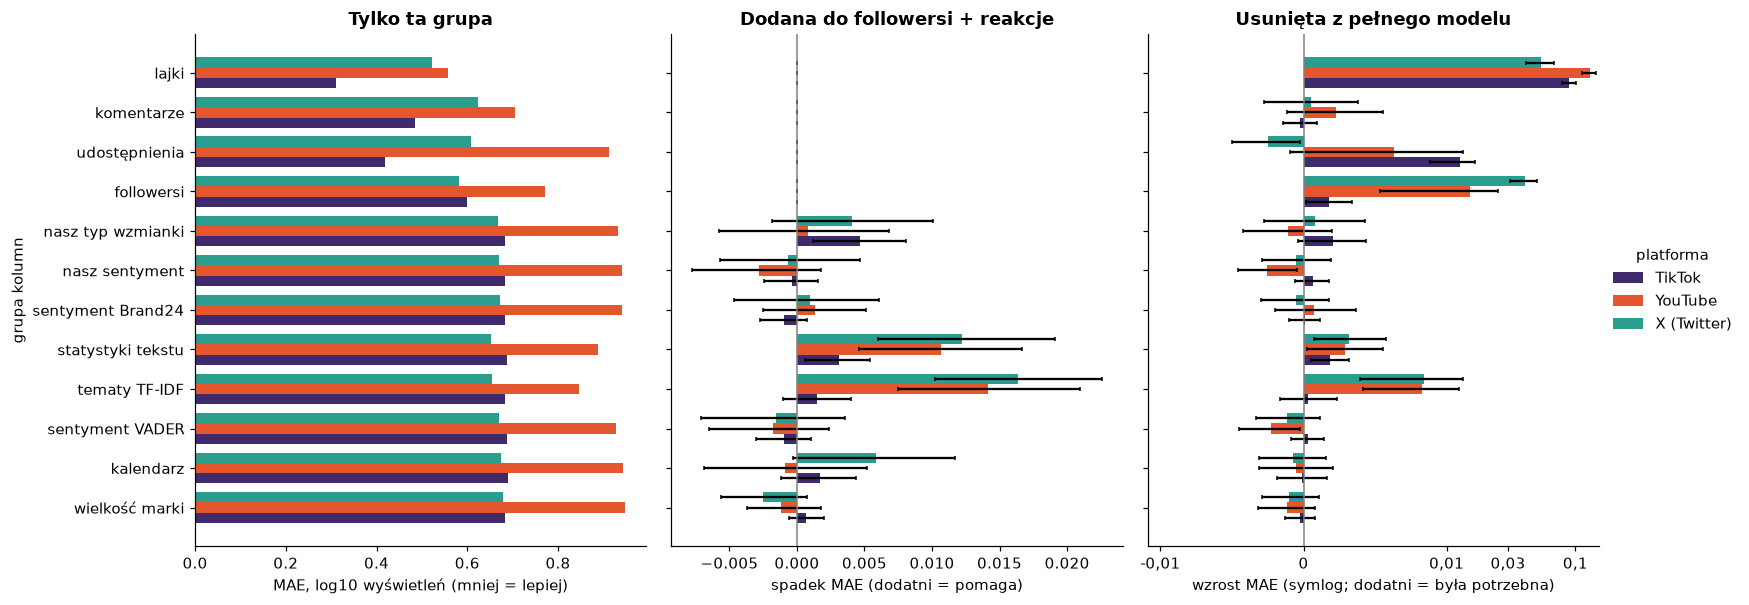

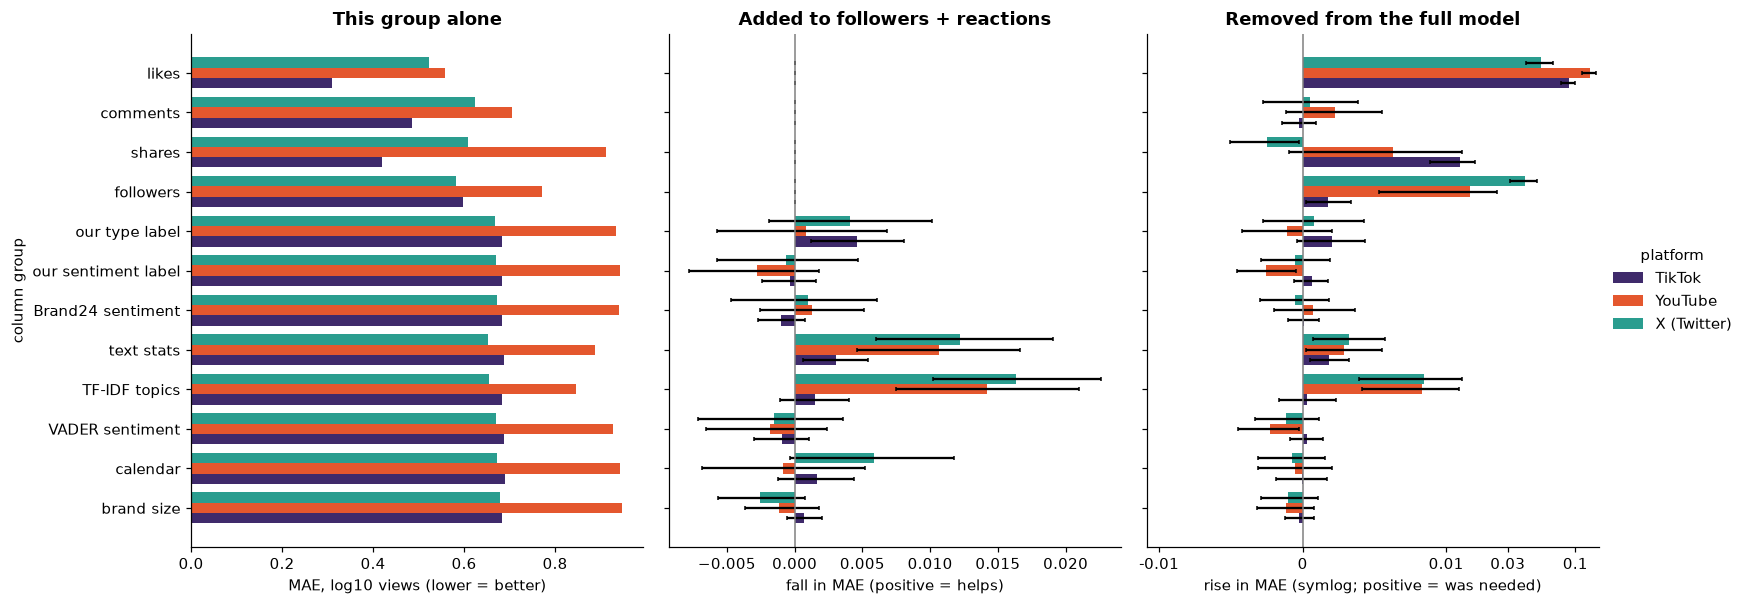

In [4]:
for l in ('pl', 'en'): la.plot_views(T, FIG / f'ablation3_{l}.png', l)

Robustness: the same ablation with a different learner.

In [5]:
T2 = pd.concat([la.three_views(P, meta, p, make=la.HGB) for p in mo.PLATS], ignore_index=True); T2.pivot(index='group', columns='platform', values='remove loss').reindex(T.group.unique()).round(3)

platform,TikTok,X (Twitter),YouTube
group,,,
likes,0.086,0.058,0.131
comments,-0.000,0.003,0.001
shares,0.011,0.002,-0.004
followers,0.002,0.045,0.023
our type label,0.002,0.003,-0.001
our sentiment label,-0.000,-0.001,-0.002
Brand24 sentiment,-0.001,0.002,-0.005
text stats,0.003,0.005,0.003
TF-IDF topics,0.002,0.016,0.007


## 2 · Single columns

In [6]:
I = pd.concat([la.column_importance(P, meta, p) for p in mo.PLATS], axis=1); I.assign(mean=I.mean(axis=1)).sort_values('mean', ascending=False).head(15).round(3)

,TikTok,YouTube,X (Twitter),mean
log_likes,0.476,0.561,0.209,0.415
log_followers,0.005,0.073,0.063,0.047
na_shares,0.000,0.126,-0.000,0.042
log_shares,0.066,0.000,0.005,0.024
log_comments,0.006,0.045,0.004,0.018
TF-IDF topics,0.001,0.019,0.013,0.011
type_promo,0.004,0.006,0.002,0.004
type_organic,0.001,0.000,0.007,0.003
chars,-0.000,0.004,0.001,0.001
n_mentions,0.001,0.000,0.003,0.001


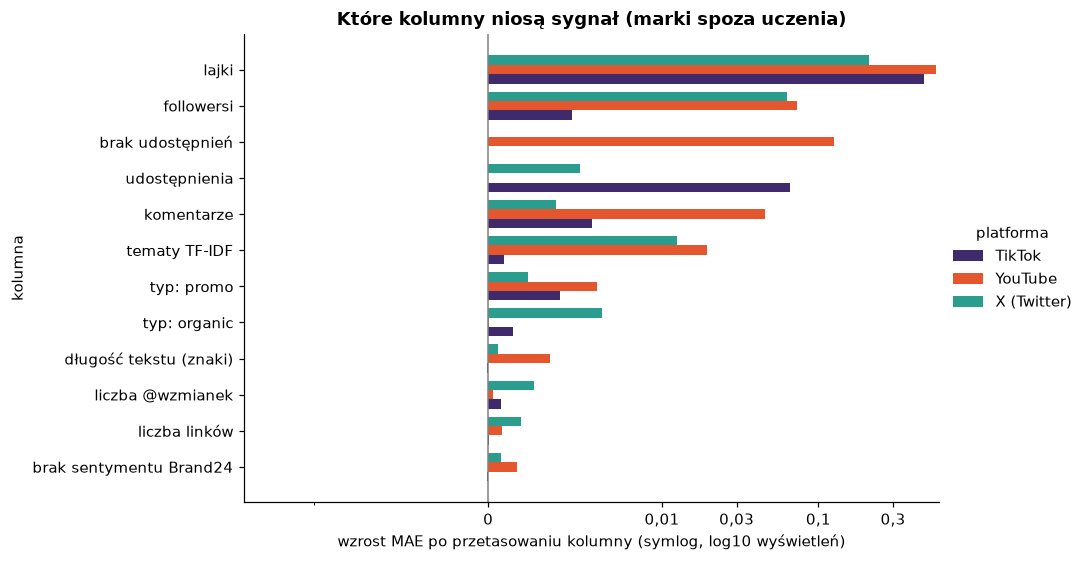

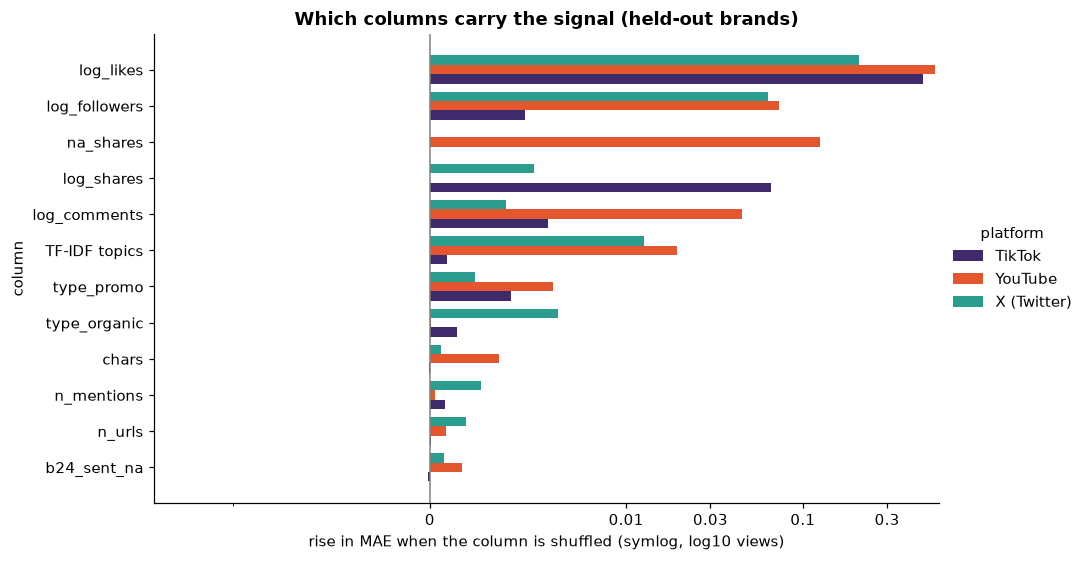

In [7]:
for l in ('pl', 'en'): la.plot_importance(I, FIG / f'importance_{l}.png', l)

## 3 · Systematic errors (bias)
True minus predicted, so positive means the model underestimates.

In [8]:
B = pd.concat([la.bias_table(f, meta, raw, lab, p) for p in mo.PLATS], ignore_index=True); B.round(3)

,platform,split,group,n,bias,low,high,MAE
0,TikTok,mention type,organic,1179,-0.038,-0.059,-0.016,0.250
1,TikTok,mention type,promo,844,0.081,0.048,0.115,0.302
2,TikTok,mention type,unclear,137,-0.089,-0.150,-0.030,0.285
3,TikTok,mention type,spam,331,-0.026,-0.072,0.031,0.311
4,TikTok,sentiment,positive,1077,-0.007,-0.030,0.017,0.263
...,...,...,...,...,...,...,...,...
66,X (Twitter),true views,60-80%,360,0.327,0.285,0.371,0.466
67,X (Twitter),true views,lowest 20%,361,-0.673,-0.714,-0.631,0.679
68,X (Twitter),true views,top 20%,361,0.562,0.483,0.632,0.678
69,X (Twitter),true views,40-60%,361,0.040,0.001,0.077,0.282


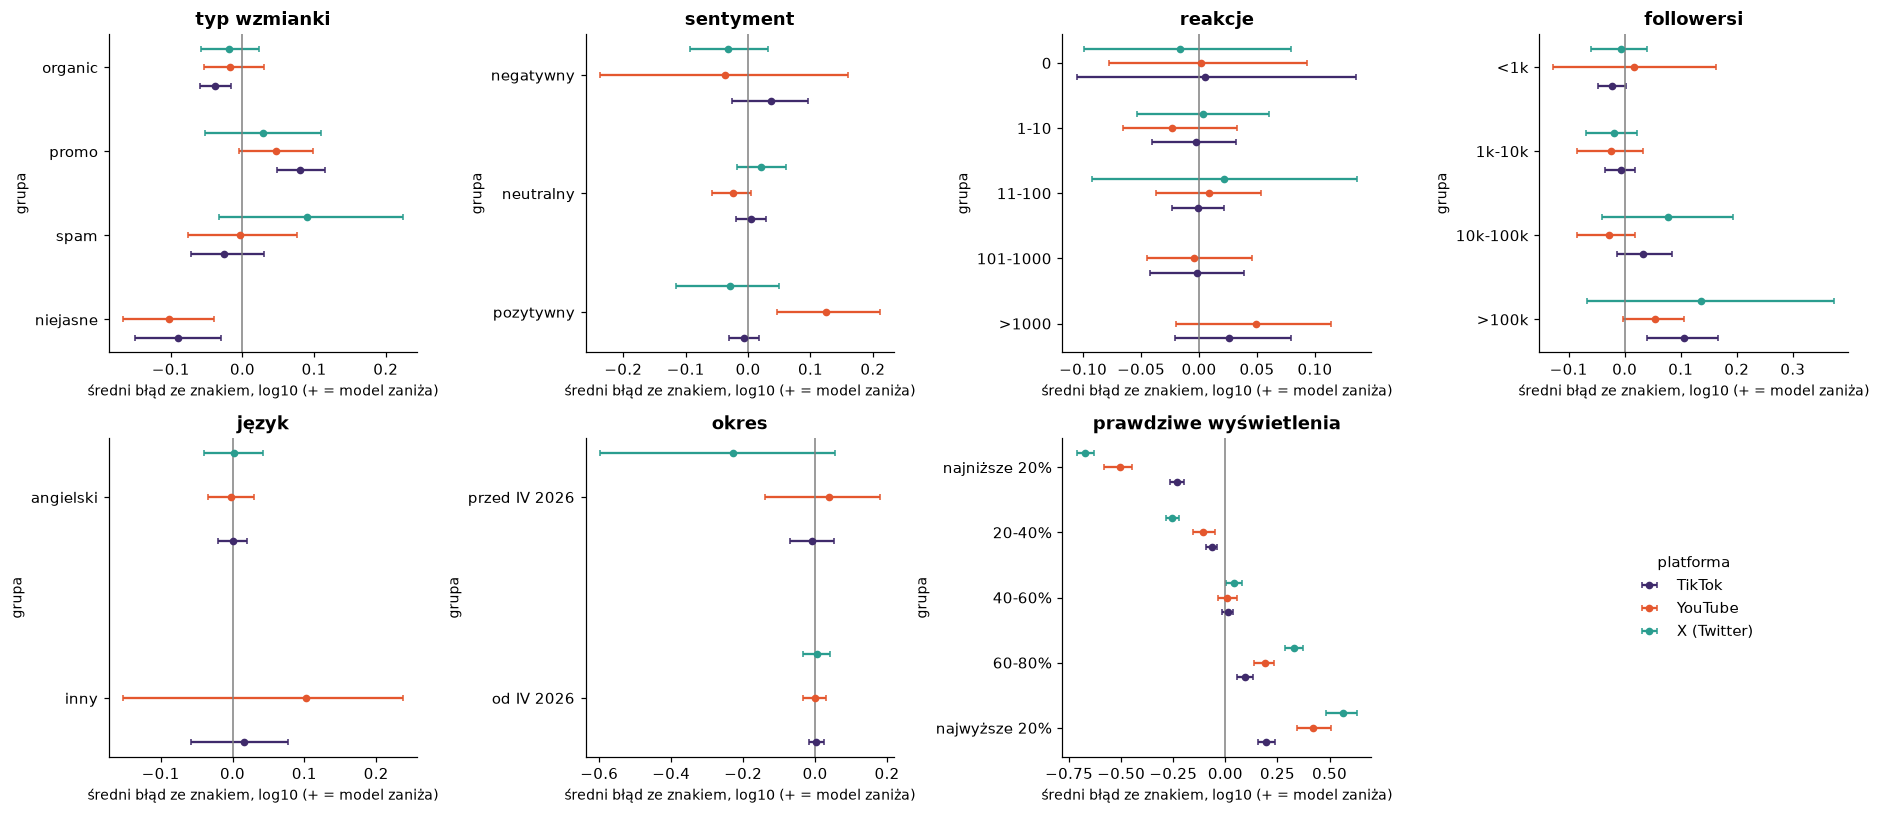

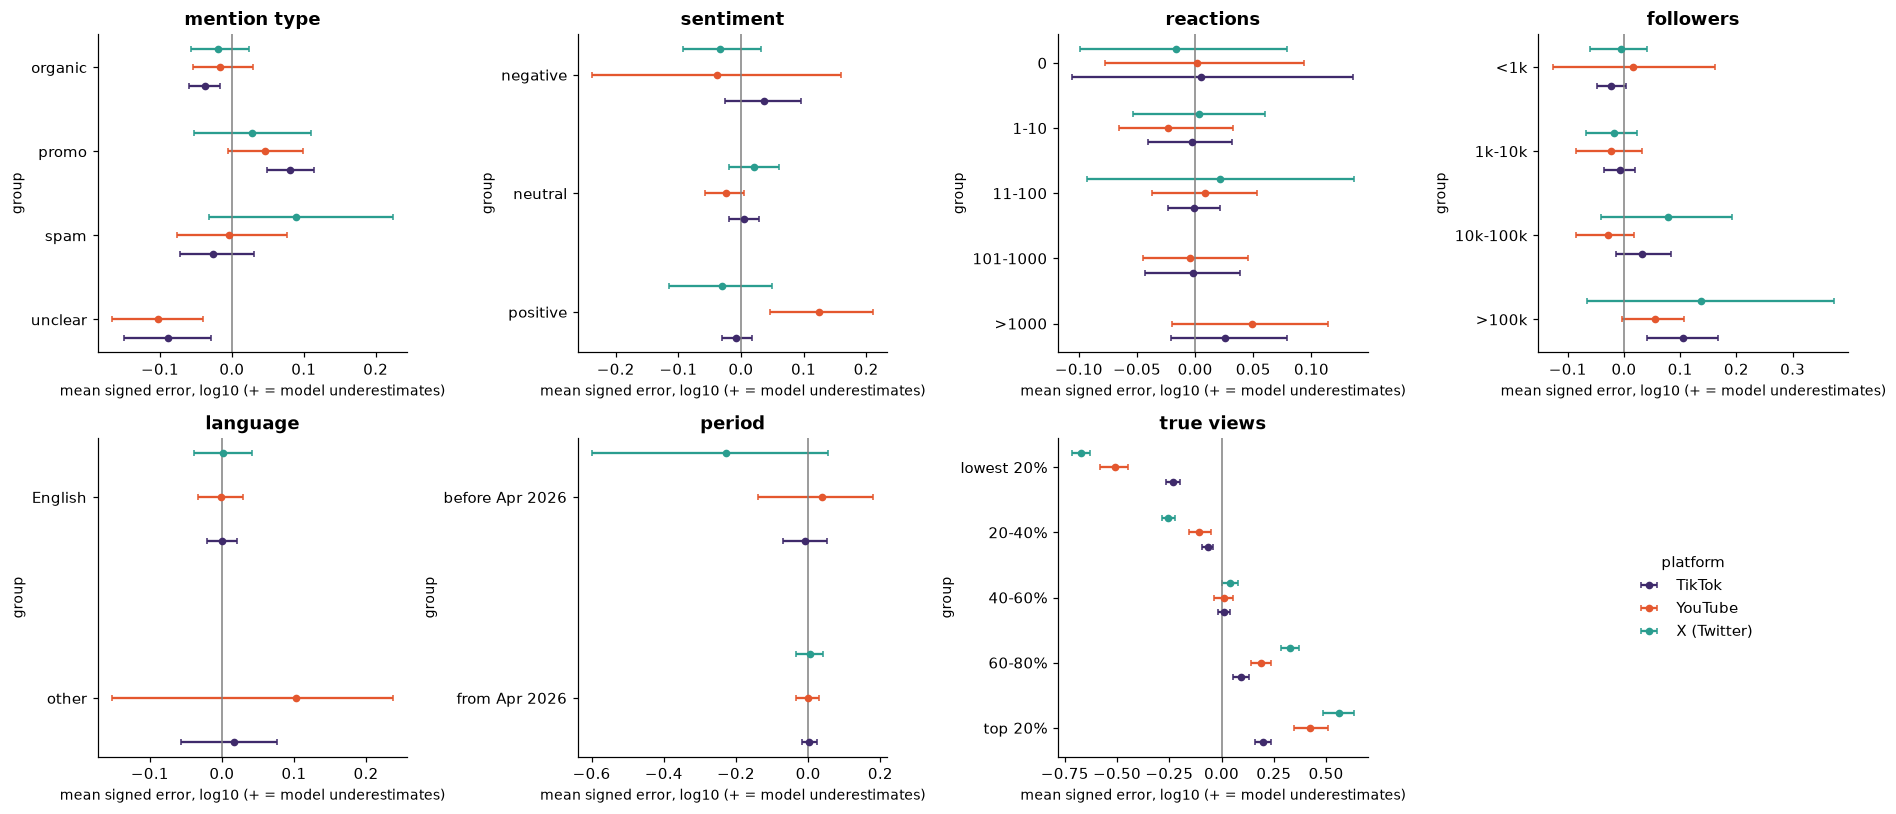

In [9]:
for l in ('pl', 'en'): la.plot_bias(B, FIG / f'bias_{l}.png', l)

## 4 · What the labels are for
Do reactions mean the same for each type? Does dropping spam from training help?

In [10]:
TL = pd.concat([la.type_lines(f, meta, lab, p) for p in mo.PLATS], ignore_index=True); TL.round(2)

,platform,type,n,slope,slope low,slope high,views at 100 reactions,level low,level high
0,TikTok,organic,1179,0.86,0.84,0.88,3.26,3.24,3.28
1,TikTok,promo,844,0.87,0.83,0.91,3.44,3.41,3.48
2,TikTok,spam,331,0.84,0.80,0.88,3.31,3.25,3.36
3,YouTube,organic,734,0.80,0.74,0.86,3.21,3.17,3.26
4,YouTube,promo,1037,0.81,0.76,0.86,3.49,3.44,3.54
5,YouTube,spam,370,0.74,0.61,0.84,3.36,3.28,3.44
6,X (Twitter),organic,1242,1.22,1.16,1.29,3.59,3.48,3.72
7,X (Twitter),promo,334,1.29,1.11,1.51,3.91,3.58,4.36
8,X (Twitter),spam,212,1.26,1.05,1.52,3.72,3.35,4.23


In [11]:
SF = pd.DataFrame([la.spam_filter(f, meta, lab, p) for p in mo.PLATS]); SF.round(3)

,platform,trained on all,spam removed,gain,low,high,spam error,non-spam error
0,TikTok,0.272,0.272,0.000,-0.001,0.002,0.311,0.272
1,YouTube,0.450,0.452,-0.002,-0.005,0.001,0.484,0.450
2,X (Twitter),0.472,0.471,0.001,-0.002,0.004,0.555,0.472


## 5 · Community detection
Louvain on the kNN text graph (TF-IDF cosine, k = 10). Uses no views and no labels.

In [12]:
C = {p: la.community_report(f, meta, raw, lab, p) for p in mo.PLATS}; CS = pd.DataFrame([C[p][0] for p in mo.PLATS]); CS.round(3)

,platform,communities,with 25+ mentions,stability (ARI across seeds),NMI with brand,NMI with our type,variance of views explained,"same, shuffled communities",variance of residual explained
0,TikTok,37,35,0.711,0.654,0.039,0.049,0.013,0.037
1,YouTube,29,22,0.614,0.487,0.080,0.092,0.010,0.024
2,X (Twitter),27,24,0.623,0.558,0.065,0.051,0.014,0.040


In [13]:
CP = pd.concat([C[p][1] for p in mo.PLATS], ignore_index=True); CP.sort_values('size', ascending=False).groupby('platform').head(8).round(2)

,platform,community,size,top terms,brands,top brand share,organic,promo,spam,unclear,median log10 views,median residual,share of platform views
35,YouTube,13,369,"https, com, www, instagram, facebook, twitter",121,0.04,0.24,0.51,0.24,0.01,2.98,0.02,0.25
36,YouTube,15,307,"gt, 039, costco, little, chipotle, caesars",83,0.06,0.46,0.10,0.04,0.40,2.51,-0.10,0.07
0,TikTok,29,250,"lexus, car, toyota, cars, ford, dodge",59,0.07,0.35,0.47,0.12,0.06,2.86,0.00,0.05
57,X (Twitter),17,208,"status, com, https, twitter, photo, bali",96,0.06,0.71,0.18,0.09,0.02,1.53,-0.08,0.07
1,TikTok,24,182,"hotel, whirlpool, inn, airbnb, hyatt, travel",54,0.12,0.42,0.47,0.09,0.02,2.76,0.04,0.01
37,YouTube,6,169,"https, com, www, amazon, shop, channel",73,0.09,0.33,0.51,0.11,0.05,2.95,-0.20,0.31
38,YouTube,11,150,"jobs, https, ai, 2025, com, salesforce",52,0.08,0.12,0.57,0.26,0.05,2.12,-0.06,0.01
58,X (Twitter),12,147,"quot, reebok, temu, like, zales, https",64,0.07,0.71,0.13,0.16,0.00,1.58,0.02,0.19
2,TikTok,17,138,"com, https, www, fedex, twitch, youtube",51,0.10,0.28,0.48,0.24,0.01,2.57,0.01,0.04
3,TikTok,1,137,"airlines, delta, shoprite, alaska, kayak, frontier",33,0.13,0.57,0.25,0.12,0.06,2.97,-0.02,0.06


In [14]:
CP.assign(z=lambda d: d.groupby("platform")["median residual"].transform(lambda s: s - s.median())).sort_values("median log10 views", ascending=False).groupby("platform").head(3)[["platform", "size", "top terms", "brands", "top brand share", "spam", "unclear", "median log10 views", "median residual"]].round(2)

,platform,size,top terms,brands,top brand share,spam,unclear,median log10 views,median residual
30,TikTok,34,"cricket, aon, viral, fyp, foryou, viralvideo",6,0.59,0.53,0.15,3.84,0.03
10,TikTok,79,"adidas, newbalance, shoes, sneakers, new, balance",12,0.38,0.11,0.01,3.35,0.16
42,YouTube,101,"amzn, https, bit, ly, http, com",55,0.09,0.17,0.00,3.10,0.18
44,YouTube,92,"lululemon, ulta, shopmy, https, sephora, haul",28,0.18,0.09,0.11,3.09,-0.09
16,TikTok,52,"cadillac, sonic, quot, texas, summer, roadhouse",22,0.25,0.15,0.00,3.04,-0.04
35,YouTube,369,"https, com, www, instagram, facebook, twitter",121,0.04,0.24,0.01,2.98,0.02
73,X (Twitter),48,"field, philadelphia, tickets, lincoln, tour, financial",20,0.33,0.17,0.00,1.85,0.38
63,X (Twitter),76,"locker, foot, balance, new, https, nike",17,0.38,0.12,0.00,1.76,0.30
59,X (Twitter),122,"bank, td, target, fargo, wells, banking",41,0.11,0.14,0.00,1.70,0.06


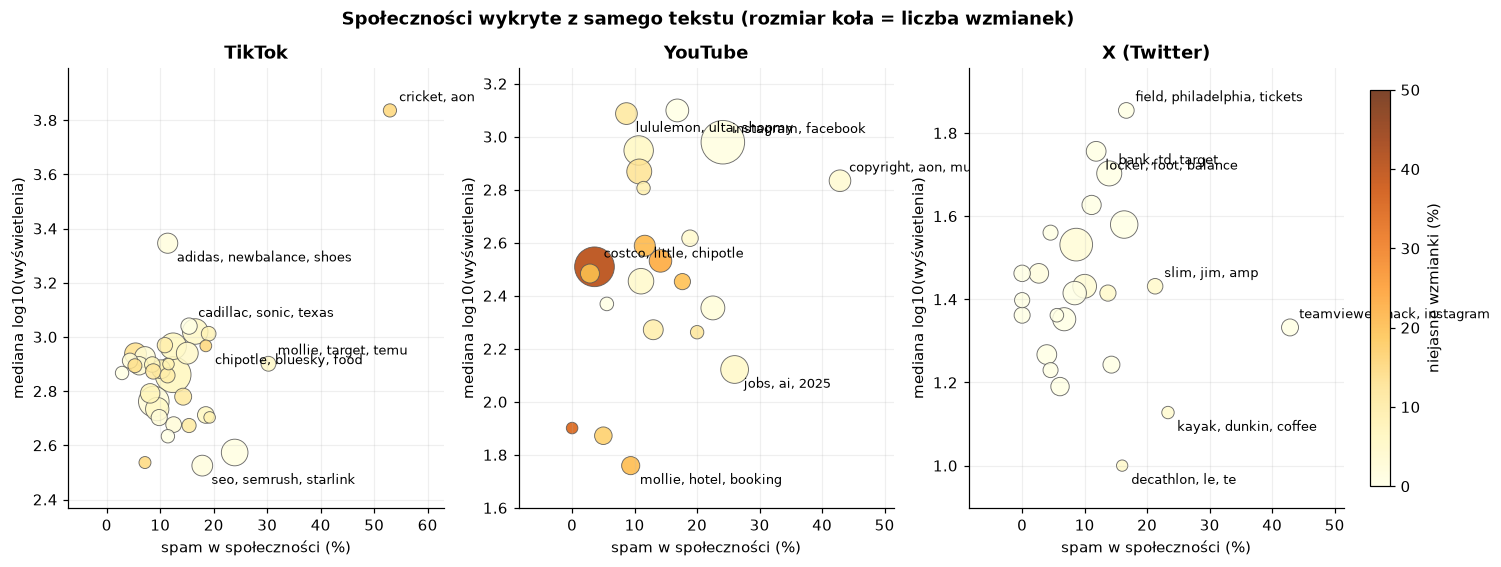

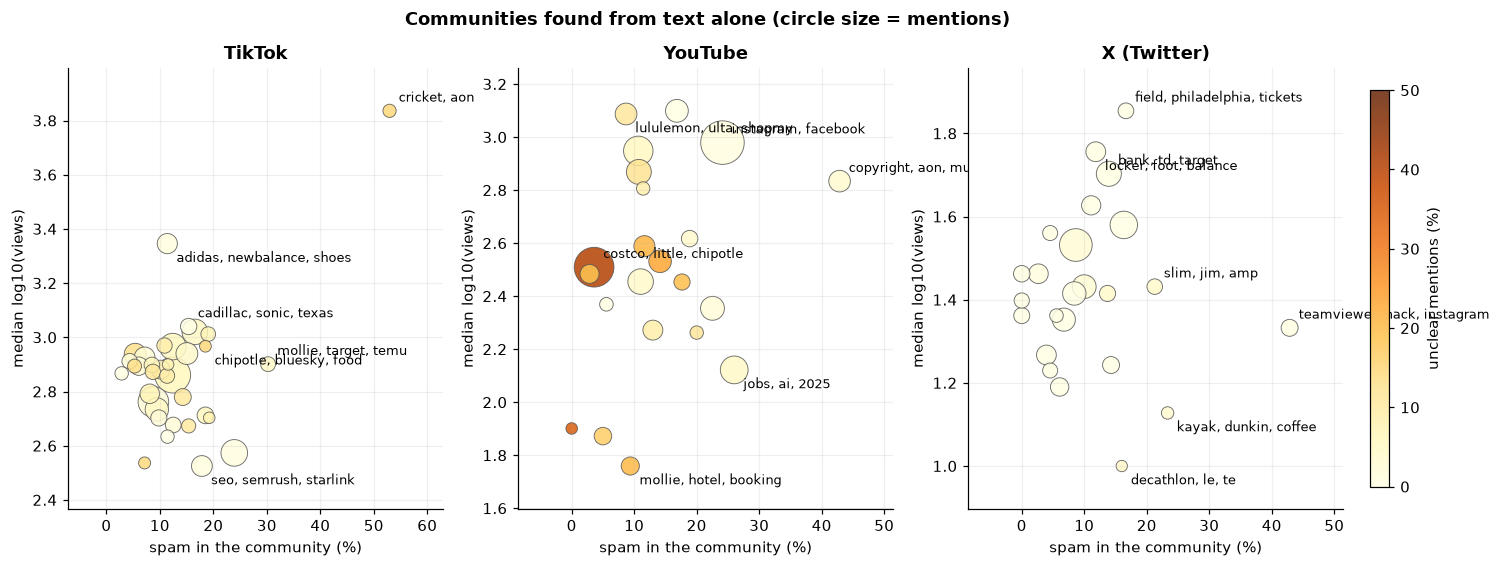

In [15]:
for l in ('pl', 'en'): la.plot_community_bubbles(CP, FIG / f'community_bubbles_{l}.png', l)

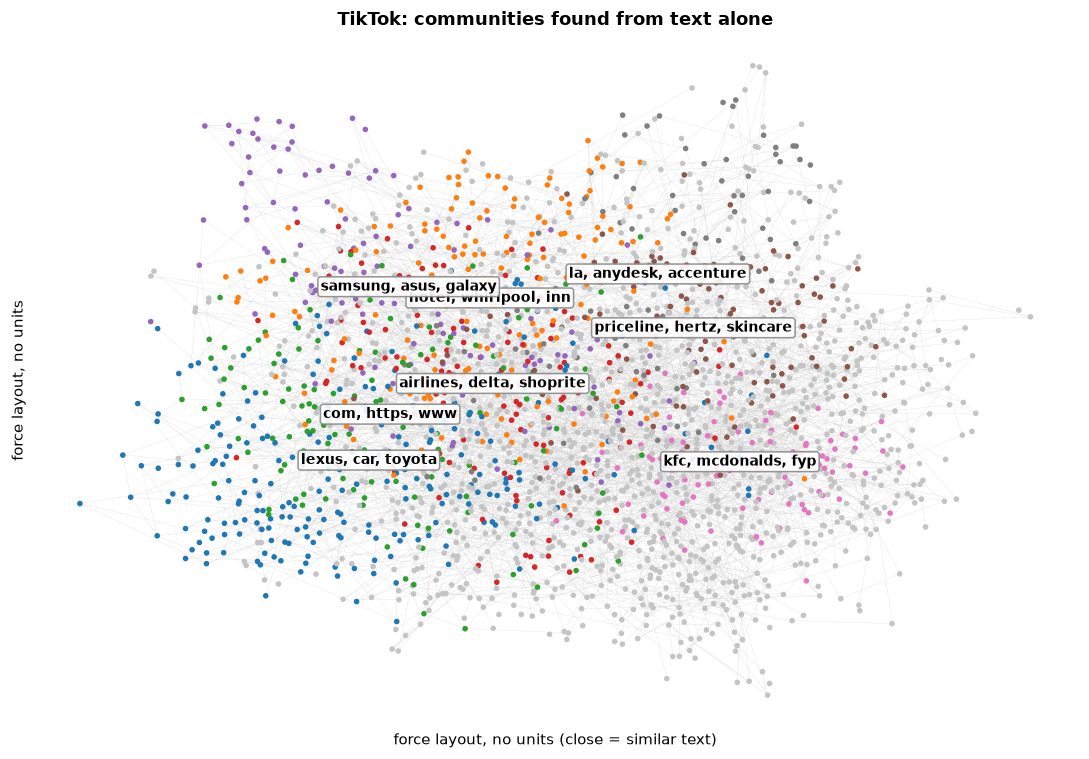

In [16]:
la.plot_community_net(C['tiktok'][2], C['tiktok'][1], 'tiktok')

### 5a · The community that is not about the brand
A small TikTok community is dominated by two brands whose names are ordinary words. Do those mentions talk about the company at all?

In [17]:
t = raw.loc[f.index]; t = t[meta.platform == "tiktok"]; txt = (t.title.fillna("") + " " + t.content.fillna("")).str.lower(); checks = [("Cricket Wireless", "wireless|phone|prepaid|plan\\b|network|5g", "ipl|match|wicket|t20|batsman|bowler|babar|kohli|#cricket"), ("Aon", "insurance|broker|reinsurance|risk|benefit", "vlog|family|#fyp|#viral")]; rows = []
for b, comp, other in checks:
    q = txt[t.brand == b]; yy = meta.y[(meta.platform == "tiktok") & (t.brand.reindex(meta.index) == b)]; rows.append({"brand": b, "mentions": len(q), "company words": q.str.contains(comp).mean(), "other-sense words": q.str.contains(other).mean(), "median log10 views": yy.median()})
FP = pd.DataFrame(rows); print("TikTok median log10 views overall:", round(meta.y[meta.platform == "tiktok"].median(), 2)); FP.round(2)

TikTok median log10 views overall: 2.86


,brand,mentions,company words,other-sense words,median log10 views
0,Cricket Wireless,20,0.0,0.75,4.21
1,Aon,10,0.2,0.70,3.79


### 5b · The YouTube community of transcripts
Some YouTube mentions match inside the spoken transcript, not the title or description. They start with a time stamp like `[21:01]`.

In [18]:
m = (meta.platform == "youtube").values; r = raw.loc[f.index][m].reset_index(drop=True); M = meta[m].reset_index(drop=True); flag = r.content.fillna("").str.match(r"^\s*\[\d+:\d+").astype(int); X = f[m][em.ENG].reset_index(drop=True); pb = em.cv_predict(la.ET, X, M.y, M.brand); pn = em.cv_predict(la.ET, X.assign(transcript=flag), M.y, M.brand); d = ni.paired_diff(M.y.values, pb, pn, M.brand.values); ty = lab[m].type.reset_index(drop=True)
TR = {"share of YouTube mentions": float(flag.mean()), "median log10 views, transcript": float(M.y[flag == 1].median()), "median log10 views, other": float(M.y[flag == 0].median()), "share unclear, transcript": float((ty[flag == 1] == "unclear").mean()), "share unclear, other": float((ty[flag == 0] == "unclear").mean()), "MAE transcript": float(np.abs(M.y - pb)[flag == 1].mean()), "MAE other": float(np.abs(M.y - pb)[flag == 0].mean()), "gain from flag": d[0], "gain low": d[1], "gain high": d[2]}; TR

{'share of YouTube mentions': 0.20811142974190905,
 'median log10 views, transcript': 2.3190748378334227,
 'median log10 views, other': 2.7283537820212285,
 'share unclear, transcript': 0.4940944881889764,
 'share unclear, other': 0.025349198137609934,
 'MAE transcript': 0.3988014818957252,
 'MAE other': 0.4697861937757432,
 'gain from flag': np.float64(0.007909079208264646),
 'gain low': np.float64(0.003399020969934391),
 'gain high': np.float64(0.01221053656701175)}

## Takeaways
- **Likes carry the signal:** removing them raises the error by 0.09 / 0.13 / 0.05. Comments and shares add little once likes are there; followers matter on X (+0.04) and YouTube (+0.015).
- **Our labels add almost nothing to the estimate:** type gains +0.005 on TikTok (CI above zero), sentiment nothing, Brand24's own sentiment nothing. A second learner agrees.
- **Labels are still useful as a lens:** at 100 reactions promo gets a factor of 1.5-2 more views than organic on TikTok and YouTube with the same slope, and the model underestimates promo on TikTok by 0.08 and overestimates unclear posts by about 0.1. Dropping spam from training does not help; spam on X is harder to predict (0.56 vs 0.47).
- **Largest bias is regression to the mean:** the lowest 20% of posts are overestimated by 0.23 / 0.51 / 0.67 and the top 20% underestimated by 0.20 / 0.42 / 0.56. No bias across reaction tiers, language or period. Viral posts stay underestimated.
- **Communities come from text alone and match brands and industries, not types** (NMI with brand 0.49-0.65, with type 0.04-0.08). Louvain is moderately stable across seeds (ARI 0.61-0.71). They explain 5-9% of the variance of views against about 1% for shuffled ones, and 2-4% of what is left after reactions.
- **Curiosity 1, false matches:** a small TikTok community collects mentions of Cricket Wireless and Aon that are mostly about the sport and a family vlog. Small sample (20 and 10 mentions), checked with keywords.
- **Curiosity 2, transcripts:** 21% of YouTube mentions match inside the spoken transcript; half of them are labelled unclear, against 2.5% of the others. A flag for this gains +0.008.

In [19]:
json.dump({"three_views": T.to_dict("records"), "robust_remove_loss": T2.to_dict("records"), "importance": I.reset_index().to_dict("records"), "bias": B.to_dict("records"), "type_lines": TL.to_dict("records"), "spam_filter": SF.to_dict("records"), "communities": CS.to_dict("records"), "community_profiles": CP.to_dict("records"), "false_positive": FP.to_dict("records"), "transcripts": TR}, open(ROOT / "data" / "processed" / "ablation_numbers.json", "w"), indent=1, default=float)